Message sent   Encoding gate   Decoded (1024 shots)
00             I               {'00': 1024}
01             X               {'01': 1024}
10             Z               {'10': 1024}
11             Z then X        {'11': 1024}


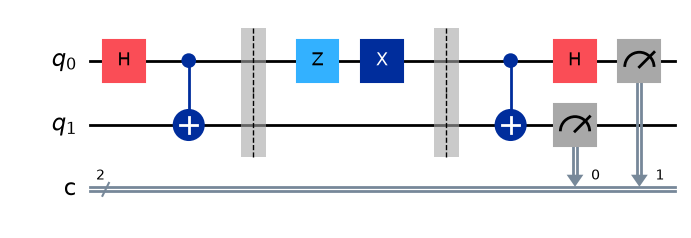

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, pauli_error, depolarizing_error
def encode_gate(qc, qubit, bits):
 """Alice's encoding operation for a 2-bit message (b1, b0)."""
 b1, b0 = bits
 if b1 == 0 and b0 == 0:
     pass # I -> message 00
 elif b1 == 0 and b0 == 1:
     qc.x(qubit) # X -> message 01
 elif b1 == 1 and b0 == 0:
     qc.z(qubit) # Z -> message 10
 elif b1 == 1 and b0 == 1:
     qc.z(qubit); qc.x(qubit) # ZX -> message 11
def superdense_coding(bits):
    qc = QuantumCircuit(2, 2)
    qc.h(0); qc.cx(0, 1) # Step 1: share a Phi+ Bell pair
    qc.barrier()
    encode_gate(qc, 0, bits) # Step 2: Alice encodes on her qubit (q0)
    qc.barrier()
    qc.cx(0, 1); qc.h(0) # Step 3: Bob decodes after receiving q0
    # q0 reveals the Z-encoded (left) bit, q1 reveals the X-encoded (right) bit
    qc.measure(0, 1); qc.measure(1, 0)
    return qc
print(f"{'Message sent':<15}{'Encoding gate':<16}{'Decoded (1024 shots)'}")
gate_name = {(0,0): 'I', (0,1): 'X', (1,0): 'Z', (1,1): 'Z then X'}
for b1 in [0, 1]:
 for b0 in [0, 1]:
    qc = superdense_coding((b1, b0))
    counts = AerSimulator().run(qc, shots=1024).result().get_counts()
    print(f"{f'{b1}{b0}':<15}{gate_name[(b1,b0)]:<16}{counts}")
display(superdense_coding((1, 1)).draw(output='mpl', style='iqp'))